# 02 · Tasks, oracle metrics and the human baseline

**Why.** A benchmark task is a pair of pages, *start* and *target*. To score an agent exactly we need, for every state it can reach, the optimal remaining cost and the information still needed to play optimally. This notebook computes those quantities for a first task set and writes the files the task viewer (`viewer/index.html`) reads. It also scores the Wikispeedia human games with the same metrics, which gives both a baseline and a first check that the information measure tracks difficulty.

**The two cost models** (defined in `wikigame/metrics.py`):

* *Click model*, the classic game. The player sees the whole page and each click costs 1. The optimum $d^*$ is the shortest path length in the page graph.
* *Action model*, the agentic benchmark. The player sees one chunk of about 2,000 characters at a time. Each action (click a visible link, scroll down, scroll up) costs 1. The optimum $V^*$ is the shortest path in the graph whose nodes are (page, chunk) pairs.

**Bits needed.** The reference is a player who picks uniformly at random among the available actions. Let $P(x)$ be the probability that this player, starting from state $x$, follows an optimal path to the target. Then $\varphi(x) = -\log_2 P(x)$ is the number of bits a player must supply to play optimally from $x$. An action from $x$ to $y$ gains $\varphi(x) - \varphi(y)$ bits. When $k$ of the $n$ available actions are optimal and lead to equally hard states, an optimal action gains exactly $\log_2(n/k)$ bits. Along any trajectory that reaches the target, the gains add up to $\varphi(\text{start})$. So a wrong move shows up as lost bits, which must be won back with extra steps.

**Runtime.** About two minutes on a laptop (mostly the oracle for 1,600 human-played pairs, 35 ms each).

In [1]:
import json, math, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

from wikigame.world import World, ROOT
from wikigame.metrics import Graphs, Oracle, score_pages, score_actions

world = World.load("wikispeedia")
g = Graphs.build(world)
GRAPH = ROOT / "data" / "raw" / "wikispeedia" / "wikispeedia_paths-and-graph"
OUT = world.dir / "tasks"
OUT.mkdir(exist_ok=True)
read_tsv = lambda name, cols: pd.read_csv(GRAPH / name, sep="\t", comment="#", header=None, names=cols, quoting=3)

## Human games

Wikispeedia logged 51,318 finished and 24,875 unfinished games. A finished game is a list of pages, where `<` marks a click on the browser's back button. We turn each game into the sequence of pages the player stood on, so a back-click becomes a move to the previous page. It is still counted as a click, as in the original game. Unfinished games (time-out or restart) count as failures. Games whose target is not one of the 4,604 articles (29 games, e.g. the misspelled *Long_peper*) are dropped.

In [2]:
def page_sequence(path: str) -> list[int] | None:
    stack, seq = [], []
    for name in path.split(";"):
        if name == "<":
            stack.pop()
        else:
            if name not in world.index:
                return None
            stack.append(world.index[name])
        seq.append(stack[-1])
    return seq

fin = read_tsv("paths_finished.tsv", ["player", "time", "seconds", "path", "rating"])
unf = read_tsv("paths_unfinished.tsv", ["player", "time", "seconds", "path", "target", "reason"])
fin["pages"] = fin.path.map(page_sequence)
unf["pages"] = unf.path.map(page_sequence)
fin["target_id"] = fin.pages.map(lambda s: s[-1] if s else None)
unf["target_id"] = unf.target.map(world.index.get)
games = pd.concat([
    fin.assign(finished=True)[["pages", "target_id", "seconds", "finished"]],
    unf.assign(finished=False)[["pages", "target_id", "seconds", "finished"]],
]).dropna(subset=["pages", "target_id"])
games["start_id"] = games.pages.map(lambda s: s[0])
games["target_id"] = games.target_id.astype(int)
print(f"{len(games):,} games, {games.finished.mean():.0%} finished")

76,164 games, 67% finished


## Oracle for every human-played pair

We compute the oracle for every (start, target) pair that people played at least 5 times, 1,671 pairs in all. Each finished game is then scored in the click model. The scores are its *efficiency*, optimal clicks divided by clicks taken (1 is perfect), and its *bits lost*, the sum of negative information gains.

In [3]:
counts = games.groupby(["start_id", "target_id"]).size()
pairs = counts[counts >= 5].index.tolist()
oracles = {}
rows = []
t0 = time.time()
for s, t in pairs:
    if t not in oracles:
        oracles[t] = Oracle(world, g, t)
    o = oracles[t]
    sub = games[(games.start_id == s) & (games.target_id == t)]
    eff, lost = [], []
    for seq in sub[sub.finished].pages:
        _, summ = score_pages(o, seq)
        eff.append(summ["efficiency"]); lost.append(summ["bits_lost"])
    x = o.state(s)
    rows.append({
        "start": s, "target": t, "d_star": int(o.d[s]), "V_star": int(o.V[x]),
        "bits_click": float(o.phi_page[s]), "bits_action": float(o.phi_state[x]), "n_shortest_paths": float(o.n_paths_to[s]),
        "human_games": len(sub), "human_success": sub.finished.mean(),
        "human_efficiency": np.mean(eff) if eff else np.nan, "human_bits_lost": np.mean(lost) if lost else np.nan,
        "human_median_seconds": sub[sub.finished].seconds.median(),
    })
pairs_df = pd.DataFrame(rows)
print(f"{len(pairs_df)} pairs, {len(oracles)} distinct targets, {time.time() - t0:.0f} s")
pairs_df.describe().T[["mean", "50%", "min", "max"]].round(2)

1671 pairs, 931 distinct targets, 26 s


,mean,50%,min,max
start,2103.97,1881.00,8.00,4591.00
target,2347.21,2310.00,9.00,4602.00
d_star,2.95,3.00,1.00,6.00
V_star,5.77,5.00,1.00,26.00
bits_click,13.15,12.98,2.58,24.69
bits_action,16.77,15.51,1.00,58.56
n_shortest_paths,16.40,6.00,1.00,259.00
human_games,12.83,6.00,5.00,2044.00
human_success,0.78,0.82,0.00,1.00
human_efficiency,0.55,0.56,0.07,1.00


## Does the information measure track difficulty for people?

If bits needed is a useful difficulty measure, tasks that need more bits should be harder for people. The test is whether it says more than the shortest-path length $d^*$ already does. We correlate both with the human success rate and with the efficiency of finished games, using Spearman's rank correlation $\rho$. The spread is a 95% bootstrap interval over pairs (1,000 resamples). Then, *within* each value of $d^*$, we check whether bits still separate easy from hard pairs.

The figure after the tables draws the same comparison and is saved to `docs/figures/human_difficulty.png`. Its left panel shows each correlation with its interval. Its right panel splits the pairs of each path length into five equal groups by bits needed and shows the mean efficiency of finished human games in each group.

In [4]:
rng = np.random.default_rng(0)
def rho_ci(x, y, n_boot=1000):
    x, y = np.asarray(x), np.asarray(y)
    ok = np.isfinite(x) & np.isfinite(y)
    x, y = x[ok], y[ok]
    boots = [spearmanr(x[i], y[i]).statistic for i in (rng.integers(0, len(x), len(x)) for _ in range(n_boot))]
    return f"{spearmanr(x, y).statistic:+.2f} [{np.percentile(boots, 2.5):+.2f}, {np.percentile(boots, 97.5):+.2f}]"

table = pd.DataFrame({
    outcome: {pred: rho_ci(pairs_df[pred], pairs_df[outcome]) for pred in ["d_star", "bits_click", "bits_action"]}
    for outcome in ["human_success", "human_efficiency"]
})
within = pd.DataFrame({
    f"d* = {d}": {outcome: rho_ci(grp.bits_click, grp[outcome]) for outcome in ["human_success", "human_efficiency"]} | {"pairs": len(grp)}
    for d, grp in pairs_df.groupby("d_star") if len(grp) >= 30
})
display(table.rename_axis("Spearman ρ with →"), within.rename_axis("bits (click model) within a fixed d*"))

,human_success,human_efficiency
Spearman ρ with →,,
d_star,"-0.16 [-0.21, -0.12]","+0.13 [+0.08, +0.18]"
bits_click,"-0.26 [-0.30, -0.21]","-0.12 [-0.17, -0.08]"
bits_action,"-0.30 [-0.34, -0.26]","-0.18 [-0.23, -0.14]"


,d* = 2,d* = 3,d* = 4
bits (click model) within a fixed d*,,,
human_success,"-0.08 [-0.19, +0.02]","-0.24 [-0.30, -0.19]","-0.12 [-0.24, +0.00]"
human_efficiency,"-0.20 [-0.29, -0.10]","-0.33 [-0.38, -0.27]","-0.23 [-0.34, -0.12]"
pairs,360,992,266


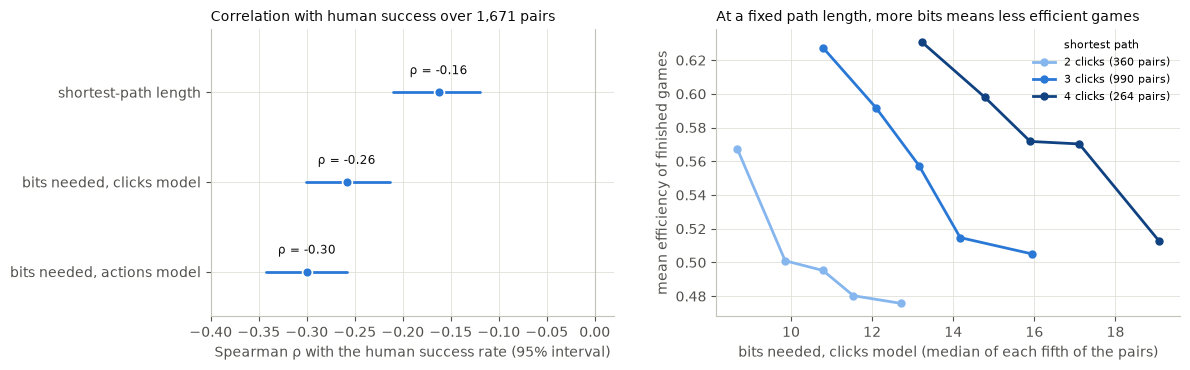

In [5]:
from wikigame import style
from wikigame.style import AXIS, BLUE, INK, INK2, SEQUENTIAL_3
style.use()

def rho_interval(x, y, n_boot=1000):
    x, y = np.asarray(x), np.asarray(y)
    ok = np.isfinite(x) & np.isfinite(y)
    x, y = x[ok], y[ok]
    boots = [spearmanr(x[i], y[i]).statistic for i in (rng.integers(0, len(x), len(x)) for _ in range(n_boot))]
    return spearmanr(x, y).statistic, np.percentile(boots, 2.5), np.percentile(boots, 97.5)

predictors = [("d_star", "shortest-path length"), ("bits_click", "bits needed, clicks model"), ("bits_action", "bits needed, actions model")]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1, 1.15]})
for i, (col, label) in enumerate(predictors):
    r, lo, hi = rho_interval(pairs_df[col], pairs_df.human_success)
    ax[0].plot([lo, hi], [i, i], color=BLUE, linewidth=2, solid_capstyle="round")
    ax[0].scatter([r], [i], s=50, color=BLUE, edgecolor="white", linewidth=1.2, zorder=3)
    ax[0].text(r, i - 0.2, f"ρ = {r:+.2f}", ha="center", fontsize=8.5, color=INK)
ax[0].set_yticks(range(len(predictors)), [label for _, label in predictors])
ax[0].set_ylim(len(predictors) - 0.5, -0.7)
ax[0].axvline(0, color=AXIS, linewidth=0.8)
ax[0].set_xlim(-0.4, 0.02)
ax[0].set_xlabel("Spearman ρ with the human success rate (95% interval)")
ax[0].set_title(f"Correlation with human success over {len(pairs_df):,} pairs", loc="left")

for d, colour in zip((2, 3, 4), SEQUENTIAL_3):
    grp = pairs_df[pairs_df.d_star == d].dropna(subset=["human_efficiency"])
    fifth = pd.qcut(grp.bits_click, 5, duplicates="drop")
    m = grp.groupby(fifth, observed=True).agg(x=("bits_click", "median"), y=("human_efficiency", "mean"))
    ax[1].plot(m.x, m.y, color=colour, marker="o", markersize=5, label=f"{d} clicks ({len(grp)} pairs)")
ax[1].set(xlabel="bits needed, clicks model (median of each fifth of the pairs)", ylabel="mean efficiency of finished games")
ax[1].legend(title="shortest path", fontsize=8, title_fontsize=8, loc="upper right")
ax[1].set_title("At a fixed path length, more bits means less efficient games", loc="left")
plt.tight_layout(w_pad=3)
style.save(fig, "human_difficulty")

## The first task set

The viewer shows a fixed set of tasks. For each $d^*$ from 1 to 6 we take the pairs people played most (at least 10 games), up to 8 per distance. Since people rarely played long tasks, we add 6 random reachable pairs with $d^*$ from 5 to 7 (seeded, no human baseline). The task list is written to `tasks/index.json`, and each task gets a file with:

* the cost-to-go and bits-to-go of every page (click model) and every (page, chunk) state (action model);
* the shortest-path graph between start and target, capped at the 24 pages per layer that carry the most shortest paths;
* one action-optimal trajectory (at each step, the optimal action that leads to the easiest next state);
* up to 60 human games.

In [6]:
PER_DISTANCE, MAX_LAYER, MAX_HUMANS = 8, 24, 60
human = pairs_df[pairs_df.human_games >= 10].sort_values("human_games", ascending=False)
chosen = pd.concat([grp.head(PER_DISTANCE) for _, grp in human.groupby("d_star")])[["start", "target"]].values.tolist()

rng = np.random.default_rng(42)
extra = []
while len(extra) < 6:
    s, t = rng.integers(0, world.n, 2)
    if t not in oracles:
        oracles[t] = Oracle(world, g, t)
    if 5 <= oracles[t].d[s] <= 7 and [s, t] not in chosen:
        extra.append([int(s), int(t)])
chosen += extra

r4 = lambda a: [None if not math.isfinite(v) else round(float(v), 3) for v in a]

def export_task(s, t):
    o = oracles.setdefault(t, Oracle(world, g, t))
    layers, edges, through = o.dag(s)
    shown = [L[np.argsort(-through[L], kind="stable")][:MAX_LAYER] for L in layers]
    shown_set = {int(v) for L in shown for v in L}
    sub = games[(games.start_id == s) & (games.target_id == t)].head(MAX_HUMANS)
    x = o.state(s)
    meta = {
        "id": f"{s}-{t}", "start": s, "target": t,
        "start_name": world.name_of(s), "target_name": world.name_of(t),
        "d_star": int(o.d[s]), "V_star": int(o.V[x]),
        "bits_click": round(float(o.phi_page[s]), 3), "bits_action": round(float(o.phi_state[x]), 3),
        "n_shortest_paths": int(o.n_paths_to[s]),
        "human_games": int(((games.start_id == s) & (games.target_id == t)).sum()),
    }
    row = pairs_df[(pairs_df.start == s) & (pairs_df.target == t)]
    if len(row):
        meta |= {k: round(float(row[k].iloc[0]), 3) for k in ["human_success", "human_efficiency", "human_bits_lost"]}
    data = meta | {
        "page_cost": o.d.tolist(), "page_bits": r4(o.phi_page),
        "state_cost": o.V.tolist(), "state_bits": r4(o.phi_state),
        "dag_layers": [[int(v) for v in L] for L in shown],
        "dag_layer_sizes": [len(L) for L in layers],
        "dag_through": {int(v): float(through[v]) for v in shown_set},
        "dag_edges": [[a, b] for a, b in edges if a in shown_set and b in shown_set],
        "optimal_actions": o.optimal_trajectory(s),
        "humans": [{"pages": [int(p) for p in seq], "finished": bool(f), "seconds": int(sec)}
                   for seq, f, sec in zip(sub.pages, sub.finished, sub.seconds)],
    }
    (OUT / f"{s}-{t}.json").write_text(json.dumps(data))
    return meta

index = [export_task(int(s), int(t)) for s, t in chosen]
(OUT / "index.json").write_text(json.dumps({"world": world.name, "chunk_chars": world.chunk_chars, "tasks": index}, indent=1))
task_table = pd.DataFrame(index).set_index("id")
task_table[["start_name", "target_name", "d_star", "V_star", "bits_click", "bits_action", "n_shortest_paths", "human_games", "human_success", "human_efficiency"]]

,start_name,target_name,d_star,V_star,bits_click,bits_action,n_shortest_paths,human_games,human_success,human_efficiency
id,,,,,,,,,,
823-1219,Cat,Dog,1,4,5.209,10.281,1,27,0.741,0.954
2241-1733,Jesus,God,1,2,5.883,5.322,1,27,1.000,1.000
305-1602,Apple,Fruit,1,1,6.087,3.807,1,20,0.950,1.000
2832-2664,Moon,Mars,1,3,5.585,9.510,1,19,1.000,0.500
1208-894,Dinosaur,China,1,4,6.492,10.511,1,16,0.938,0.658
2656-2991,Mario,Nintendo,1,1,4.170,1.585,1,15,1.000,0.872
3011-768,North America,Canada,1,3,6.267,8.443,1,14,1.000,0.894
490-3953,Batman,Superman,1,1,2.585,1.000,1,11,1.000,1.000
535-3939,Beer,Sun,2,4,12.761,11.247,1,142,0.697,0.591


## A worked example

The action-optimal trajectory for the first task, step by step. Each row is one action: its cost-to-go before and after (a drop of 1 means the action was optimal), the number of available and optimal actions, the bits a random choice would need ($\log_2 n/k$), and the bits actually gained.

In [7]:
first = index[0]
o = oracles[first["target"]]
steps, summary = score_actions(o, first["start"], o.optimal_trajectory(first["start"]))
show = pd.DataFrame(steps)
show["page"] = show.page.map(world.name_of)
show["to_page"] = show.to_page.map(world.name_of)
print(first["start_name"], "→", first["target_name"], summary)
show[["action", "page", "chunk", "to_page", "cost_before", "cost_after", "n_actions", "n_optimal", "chance_bits", "info_gain"]].round(2)

Cat → Dog {'success': True, 'steps': 4, 'optimal_steps': 4, 'regret': 0, 'efficiency': 1.0, 'bits_needed': 10.280956313831057, 'bits_lost': 0.0, 'first_error': None}


,action,page,chunk,to_page,cost_before,cost_after,n_actions,n_optimal,chance_bits,info_gain
0,scroll_down,Cat,0,Cat,4,3,9,2,2.17,3.11
1,click,Cat,1,Rabbit,3,2,6,1,2.58,2.58
2,scroll_down,Rabbit,0,Rabbit,2,1,6,1,2.58,2.58
3,click,Rabbit,1,Dog,1,0,4,1,2.00,2.00
